In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv("../data/creditcard.csv")

In [3]:
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (284807, 31)

First 5 rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
print("\nMissing values:", df.isnull().sum().sum())
print("\nClass distribution:")
print(df["Class"].value_counts())


Missing values: 0

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64


In [5]:
print("\nFraud percentage:")
print(round(df["Class"].mean() * 100, 4), "%")


Fraud percentage:
0.1727 %


In [6]:
# Dataset information
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe().T)

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes.value_counts())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995



Duplicate Rows: 1081

Data Types:
float64    30
int64       1
Name: count, dtype: int64


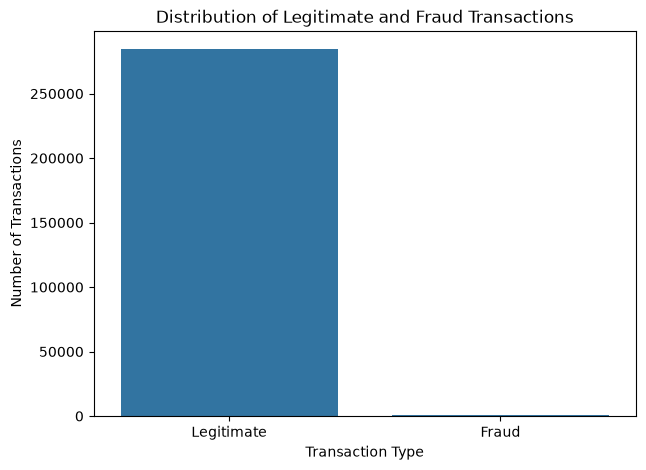

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

class_counts = df["Class"].value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.title("Distribution of Legitimate and Fraud Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.show()

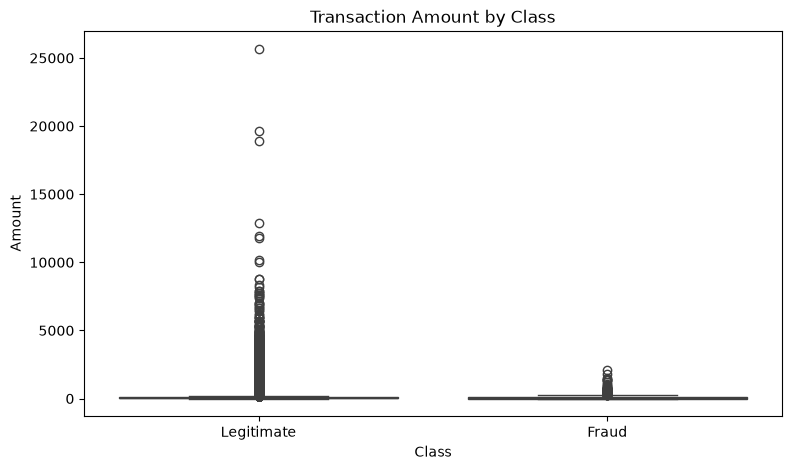

In [8]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.title("Transaction Amount by Class")
plt.show()

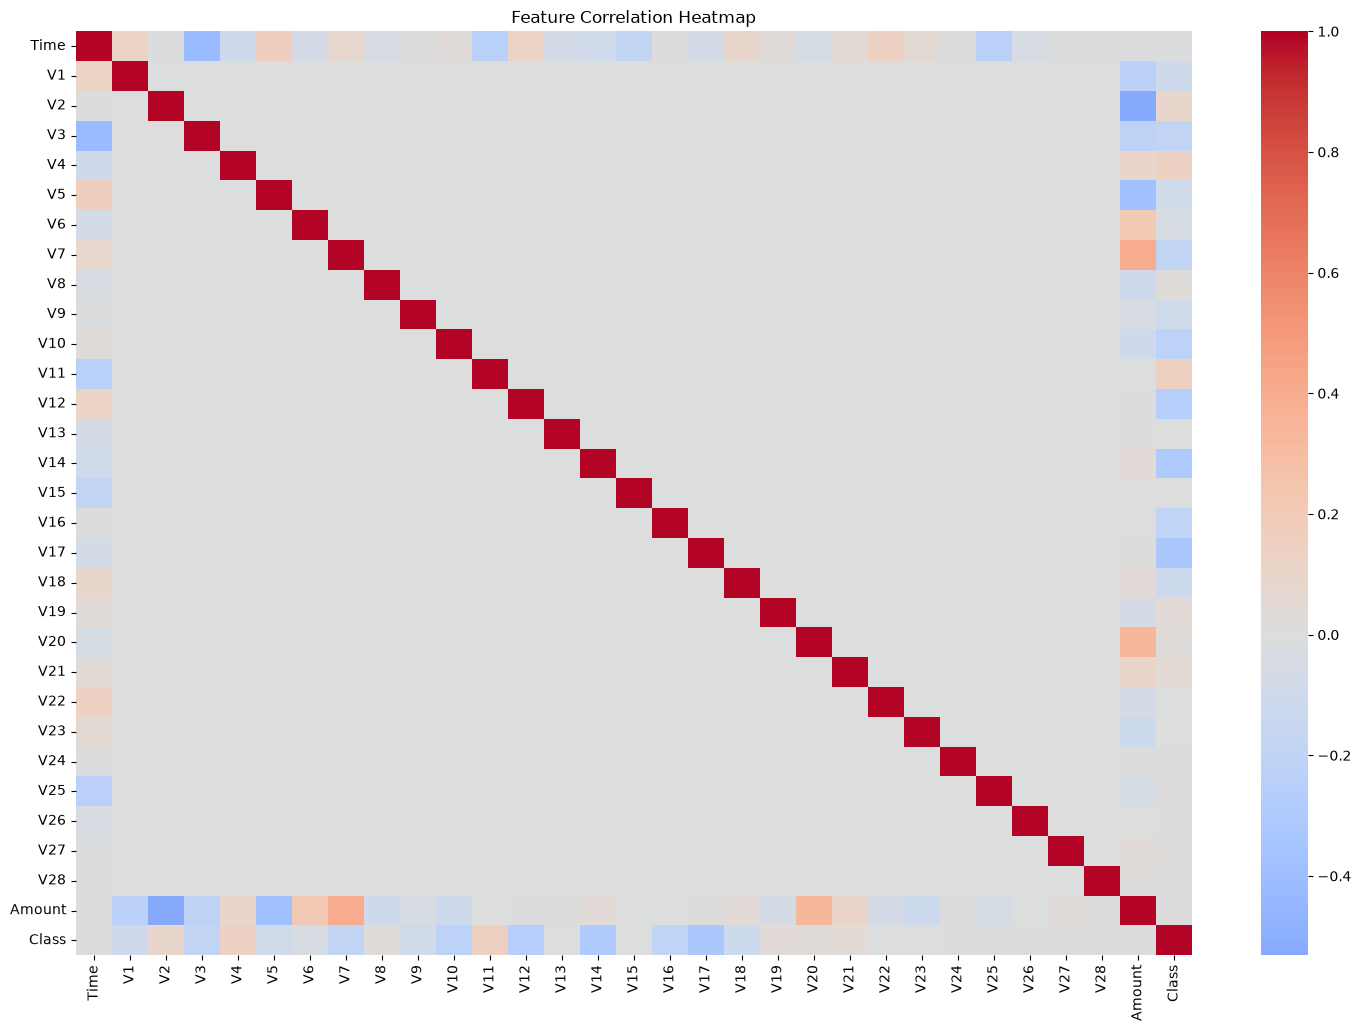

In [9]:
plt.figure(figsize=(18, 12))

correlation = df.corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Feature Correlation Heatmap")
plt.show()

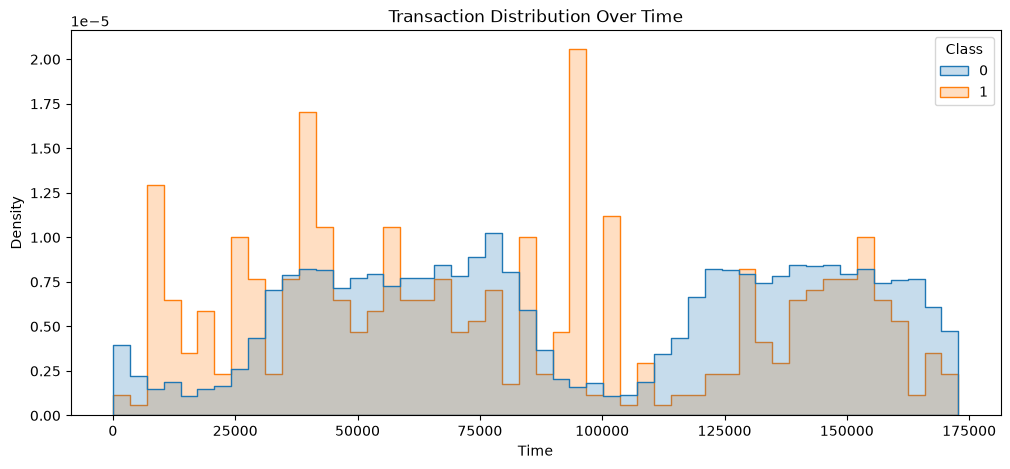

In [10]:
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="Time",
    hue="Class",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Distribution Over Time")
plt.show()

In [11]:
# Investigate exact duplicate rows
duplicate_mask = df.duplicated(keep=False)

print("Duplicate rows including first occurrences:",
      duplicate_mask.sum())

print("\nDuplicate rows beyond first occurrence:",
      df.duplicated().sum())

print("\nClass distribution among duplicated rows:")
print(df.loc[duplicate_mask, "Class"].value_counts())

# Check whether identical transaction features have different labels
feature_columns = df.columns.drop("Class")

feature_duplicates = df.duplicated(
    subset=feature_columns,
    keep=False
)

print("\nFeature duplicates with labels:")
print(df.loc[feature_duplicates, "Class"].value_counts())

Duplicate rows including first occurrences: 1854

Duplicate rows beyond first occurrence: 1081

Class distribution among duplicated rows:
Class
0    1822
1      32
Name: count, dtype: int64

Feature duplicates with labels:
Class
0    1822
1      32
Name: count, dtype: int64


In [12]:
fraud_corr = df.corr()["Class"].drop("Class")

print("Top 10 positively correlated features:")
display(fraud_corr.sort_values(ascending=False).head(10))

print("Top 10 negatively correlated features:")
display(fraud_corr.sort_values().head(10))


Top 10 positively correlated features:


V11       0.154876
V4        0.133447
V2        0.091289
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
V28       0.009536
Amount    0.005632
Name: Class, dtype: float64

Top 10 negatively correlated features:


V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
V3    -0.192961
V7    -0.187257
V18   -0.111485
V1    -0.101347
V9    -0.097733
Name: Class, dtype: float64

In [13]:
print("Amount statistics by transaction class:")

display(
    df.groupby("Class")["Amount"].agg(
        ["mean", "median", "std", "min", "max"]
    )
)

Amount statistics by transaction class:


,mean,median,std,min,max
Class,,,,,
0,88.291022,22.00,250.105092,0.0,25691.16
1,122.211321,9.25,256.683288,0.0,2125.87


In [14]:
# Check whether identical features have different fraud labels

feature_columns = df.columns.drop("Class")

label_conflicts = (
    df.groupby(list(feature_columns))["Class"]
    .nunique()
)

print("Feature groups with conflicting labels:",
      (label_conflicts > 1).sum())

Feature groups with conflicting labels: 0


In [15]:
df_clean = df.drop_duplicates().copy()

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Removed rows:", len(df) - len(df_clean))

print("\nUpdated class distribution:")
print(df_clean["Class"].value_counts())

Original dataset: (284807, 31)
Cleaned dataset: (283726, 31)
Removed rows: 1081

Updated class distribution:
Class
0    283253
1       473
Name: count, dtype: int64


In [16]:
# Sort transactions chronologically
df_clean = df_clean.sort_values("Time").reset_index(drop=True)

# Calculate split positions
n = len(df_clean)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Split chronologically
train_df = df_clean.iloc[:train_end].copy()

val_df = df_clean.iloc[train_end:val_end].copy()

test_df = df_clean.iloc[val_end:].copy()

# Check dataset sizes
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

# Check fraud distribution
for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name} class distribution:")
    print(data["Class"].value_counts())
    print("Fraud percentage:",
          round(data["Class"].mean() * 100, 4), "%")

Training: (198608, 31)
Validation: (42559, 31)
Testing: (42559, 31)

Train class distribution:
Class
0    198242
1       366
Name: count, dtype: int64
Fraud percentage: 0.1843 %

Validation class distribution:
Class
0    42504
1       55
Name: count, dtype: int64
Fraud percentage: 0.1292 %

Test class distribution:
Class
0    42507
1       52
Name: count, dtype: int64
Fraud percentage: 0.1222 %
